# Constructed Stimuli rather than Found Text

Thesis: *Corpus Construction*, section *Constructed Stimuli rather than Found Text*.

DEplain and LeiKo were not available for the stored outputs, so their columns are carried over from the stored table, as the comparison does for every missing source.

**Requirements**
- Environment: `easy-language` (`environment-easy-language.yml`)
- Packages: pandas, matplotlib, seaborn, pyphen
- Data: `data/corpus/anchor_candidates_raw.csv`, `exports/ls_metrics_sd.csv`, `exports/ls_metrics_ls.csv` (in this repository)
- External corpora, each optional: ELGEPA from the sibling repository `easy-language-gender-bias`, a DEplain checkout under `data/external/DEPlain`, LeiKo 1.5
- GPU and network: not needed

**Writes:** `figures/elgepa-attrition.pdf`, `exports/ecological_register_comparison.csv`

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "corpus").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src" / "corpus"))

import re

import matplotlib.pyplot as plt
import seaborn as sns

from readability import syllable_count
import pandas as pd
from IPython.display import display

## The ELGEPA mining pass

Found GAL text does not supply the stimuli the design needs. Of 516 fully paired sentences, 58 profession candidates remain and 3 pass the structural gate (left). Of the 13 stems with a hit, only Sekretär reaches a stereotype pole unambiguously on the Misersky et al. (2014) norm (right); a horizontal range marks a stem that matches several norm entries.

In [2]:
CANDIDATES_CSV = Path("data/corpus/anchor_candidates_raw.csv")
FIG_PATH = Path("figures/elgepa-attrition.pdf")

FUNNEL_STAGES = [
    ("Fully paired\nsentences", 516),
    ("Deduplicated profession-\nstem candidates", 58),
    ("Pass the structural\ngate (Req. scenes)", 3),
]

MISERSKY_POINT = {
    "dolmetsch": 0.60,   # Interpreters
    "übersetz": 0.64,    # Translators
    "sekretär": 0.80,    # Secretaries
    "anwalt": 0.41,      # Lawyers
    "arzt": 0.455,       # mean(Medical doctors .43, Physicians .48)
}
MISERSKY_RANGE = {
    "berater": (0.24, 0.44),  # IT consultants .. Tax advisors
    "fahrer": (0.15, 0.37),   # Lorry drivers .. generic Drivers
    "lehrer": (0.39, 0.89),   # Head teachers .. Infant teachers
    "betreu": (0.28, 0.64),   # Caretakers .. Care workers
}
NO_MATCH = ["mitarbeiter", "vermiet", "helfer", "patient"]  # not a single occupation

CORPUS_MALE_POLE = (0.16, 0.22)
CORPUS_FEMALE_POLE = (0.75, 0.79)

BLUE, GRAY, RED = "#2a78d6", "#6b6a66", "#e34948"


def stereotype_color(value: float) -> str:
    if value <= 0.35:
        return BLUE
    if value >= 0.65:
        return RED
    return GRAY


def stem_counts() -> dict[str, int]:
    return pd.read_csv(CANDIDATES_CSV, dtype=str)["matched_stem"].value_counts().to_dict()


def plot(counts: dict[str, int]) -> None:
    sns.set_theme(style="whitegrid", font_scale=1.0)
    fig, (ax_funnel, ax_val) = plt.subplots(
        1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1, 1.5]}
    )

    # --- left: attrition funnel ---
    labels = [s[0] for s in FUNNEL_STAGES][::-1]
    values = [s[1] for s in FUNNEL_STAGES][::-1]
    ax_funnel.barh(labels, values, color=BLUE, height=0.55)
    ax_funnel.set_xscale("log")
    for y, v in enumerate(values):
        ax_funnel.text(v * 1.15, y, str(v), va="center", ha="left", color="#0b0b0b", fontsize=11)
    ax_funnel.set_xlabel("Sentences / candidates (log scale)")
    ax_funnel.set_title("ELGEPA mining attrition", loc="left", fontsize=12)
    ax_funnel.set_xlim(1, max(values) * 3)
    sns.despine(ax=ax_funnel, left=True, bottom=False)

    # --- right: found stems on the Misersky stereotypicality scale ---
    point_stems = sorted(MISERSKY_POINT, key=MISERSKY_POINT.get)
    range_stems = sorted(MISERSKY_RANGE, key=lambda s: sum(MISERSKY_RANGE[s]) / 2)
    ordered = point_stems + range_stems  # NO_MATCH stems listed in caption, not plotted here
    y_pos = list(range(len(ordered)))

    ax_val.axvspan(*CORPUS_MALE_POLE, color=BLUE, alpha=0.12, lw=0)
    ax_val.axvspan(*CORPUS_FEMALE_POLE, color=RED, alpha=0.12, lw=0)
    ax_val.text(sum(CORPUS_MALE_POLE) / 2, len(ordered) - 0.3, "corpus\nmale pole",
                ha="center", va="bottom", fontsize=7.5, color=BLUE)
    ax_val.text(sum(CORPUS_FEMALE_POLE) / 2, len(ordered) - 0.3, "corpus\nfemale pole",
                ha="center", va="bottom", fontsize=7.5, color=RED)
    ax_val.axvline(0.5, color="#9c9b95", lw=1, ls="--", zorder=1)

    for y, s in zip(y_pos, ordered):
        n = counts[s]
        if s in MISERSKY_POINT:
            v = MISERSKY_POINT[s]
            ax_val.scatter([v], [y], color=stereotype_color(v), s=70, zorder=3)
            ax_val.text(v, y - 0.32, f"{v:.2f}", ha="center", fontsize=7.5, color="#0b0b0b")
        else:
            lo, hi = MISERSKY_RANGE[s]
            ax_val.plot([lo, hi], [y, y], color="#9c9b95", lw=4, solid_capstyle="round", zorder=2)
            ax_val.scatter([lo, hi], [y, y], color=[stereotype_color(lo), stereotype_color(hi)],
                            s=30, zorder=3)
            ax_val.text((lo + hi) / 2, y - 0.32, f"{lo:.2f}–{hi:.2f}",
                         ha="center", fontsize=7.5, color="#0b0b0b")

    ax_val.set_yticks(y_pos)
    ax_val.set_yticklabels([f"{s} (n={counts[s]})" for s in ordered], fontsize=9)
    ax_val.invert_yaxis()
    ax_val.set_xlim(0, 1)
    ax_val.set_xlabel("Misersky et al. (2014) German stereotypicality value")
    ax_val.set_title("Found stems on the corpus's own norm scale", loc="left", fontsize=12)
    sns.despine(ax=ax_val, left=True, bottom=False)

    note = "no single-occupation match: " + ", ".join(NO_MATCH)
    fig.text(0.99, 0.01, note, ha="right", va="bottom", fontsize=8, color="#52514e", style="italic")

    fig.tight_layout(rect=(0, 0.05, 1, 1))
    FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_PATH, bbox_inches="tight")
    print(f"-> {FIG_PATH}")

-> figures/elgepa-attrition.pdf


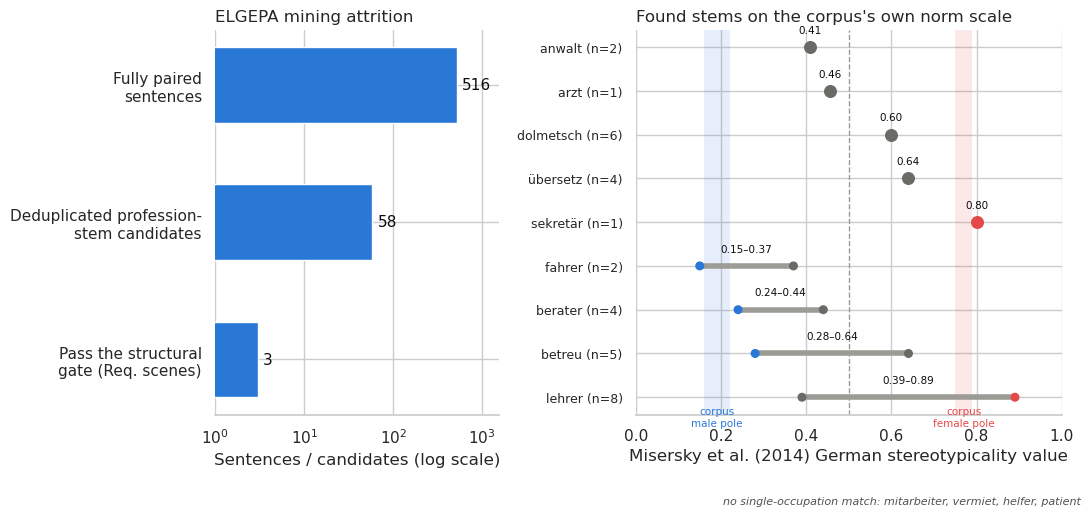

In [3]:
plot(stem_counts())

## Ecological register distance

How large the constructed GAL/GSL distance is against real-world text: the constructed delta of each readability measure as a fraction of the delta in ELGEPA and DEplain, with LeiKo as a GAL reference. On three of the four measures it is about a third to a little under half of the ecological distance. A corpus whose files are missing is carried over from the existing CSV.

In [4]:
OUT_PATH = Path("exports/ecological_register_comparison.csv")
CONSTRUCTED_SD_CSV = Path("exports/ls_metrics_sd.csv")
CONSTRUCTED_LS_CSV = Path("exports/ls_metrics_ls.csv")

DEPLAIN_LS_CORPUS_NAME = "Märchen In Leichter Sprache"
LEIKO_LS_DIRS = ("ndr", "tazleicht")  # LeiKo_1.5.meta: "Leichte Sprache: ndr, tazleicht"

SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")

FEATURES = ["wsf1", "flesch_de", "lix", "mean_sentence_length"]
FEATURE_LABELS = {
    "wsf1": "Wiener Sachtextformel",
    "flesch_de": "Amstad-Flesch-DE",
    "lix": "LIX",
    "mean_sentence_length": "Mean sentence length (words)",
}


def split_sentences(text: str) -> list[str]:
    return [s for s in SENTENCE_SPLIT.split(text.strip()) if s]


def pooled_formulas(items: list[str]) -> dict:
    """Pooled WSF / Amstad-Flesch-DE / LIX + mean sentence length over a bag of texts."""
    n_sentences = 0
    words: list[str] = []
    for text in items:
        sentences = split_sentences(text) or [text]
        n_sentences += len(sentences)
        words.extend(text.split())
    clean = ["".join(c for c in w if c.isalpha()) for w in words]
    clean = [w for w in clean if w]
    syls = [syllable_count(w) for w in clean]
    sl = len(clean) / n_sentences
    asw = sum(syls) / len(clean)
    ms = 100 * sum(1 for s in syls if s >= 3) / len(clean)
    iw = 100 * sum(1 for w in clean if len(w) > 6) / len(clean)
    es = 100 * sum(1 for s in syls if s == 1) / len(clean)
    return {
        "n_sentences": n_sentences,
        "n_words": len(clean),
        "mean_sentence_length": round(sl, 2),
        "wsf1": round(0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875, 2),
        "flesch_de": round(180 - sl - 58.5 * asw, 2),
        "lix": round(sl + iw, 2),
    }


def load_deplain(csv_path: Path) -> tuple[list[str], list[str]]:
    """Returns (sd_texts, ls_texts) for the DEplain-web Maerchen-in-Leichter-Sprache subset."""
    rows = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
    rows = rows[rows["corpus"] == DEPLAIN_LS_CORPUS_NAME].to_dict("records")
    if not rows:
        raise ValueError(
            f"no rows with corpus == {DEPLAIN_LS_CORPUS_NAME!r} in {csv_path} "
            "(check the DEplain checkout / corpus label spelling)"
        )
    return [r["original"] for r in rows], [r["simplification"] for r in rows]


def load_elgepa(csv_path: Path) -> tuple[list[str], list[str]]:
    """Returns (sd_texts, ls_texts) for ELGEPA's actor-bearing sentence pairs: the rows of the main
    project's actor_prompts_paired.csv where both context sentences are non-empty.
    """
    rows = [r for r in pd.read_csv(csv_path, dtype=str, keep_default_na=False).to_dict("records")
            if r["normal_context_sentence"].strip() and r["simple_context_sentence"].strip()]
    if not rows:
        raise ValueError(f"no rows with both context sentences filled in {csv_path}")
    return ([r["normal_context_sentence"] for r in rows],
            [r["simple_context_sentence"] for r in rows])


def load_leiko(base_dir: Path) -> list[str]:
    """Returns pooled sentence texts for LeiKo's Leichte-Sprache subset (ndr + tazleicht),
    reconstructed from the blank-line-delimited CoNLL-like pos_dep export (surface form is column 2
    of each token row).
    """
    sentences: list[str] = []
    for sub in LEIKO_LS_DIRS:
        d = base_dir / sub
        if not d.is_dir():
            raise FileNotFoundError(f"expected LeiKo subfolder not found: {d}")
        for csv_file in d.glob("*.csv"):
            text = csv_file.read_text(encoding="utf-8")
            for block in text.split("\n\n"):
                tokens = [line.split("\t")[1] for line in block.splitlines() if line.strip()]
                if tokens:
                    sentences.append(" ".join(tokens))
    return sentences


def load_constructed() -> tuple[list[str], list[str]]:
    sd_texts = pd.read_csv(CONSTRUCTED_SD_CSV, dtype=str, keep_default_na=False)["text"].tolist()
    ls_texts = pd.read_csv(CONSTRUCTED_LS_CSV, dtype=str, keep_default_na=False)["text"].tolist()
    return sd_texts, ls_texts


def report_delta(label: str, sd: dict, ls: dict) -> dict:
    return {f: round(ls[f] - sd[f], 4) for f in FEATURES} | {"source": label}

In [5]:
DEPLAIN_CSV = Path("data/external/DEPlain/E__Sentence-level_Corpus/DEplain-web-sent/manual/open/test.csv")
LEIKO_DIR = Path("data/external/LeiKo_1.5/LeiKo_1.5_pos_dep/LeiKo_1.5")
ELGEPA_CSV = ROOT.parent / "easy-language-gender-bias/data/processed/actor_prompts_paired.csv"

In [6]:
previous = {}
if OUT_PATH.exists():
    previous = (pd.read_csv(OUT_PATH, dtype=str, keep_default_na=False)
                .set_index("feature", drop=False).to_dict("index"))

def carried(feat: str, *columns: str):
    """Value of the first column present in the previous run's row, or None."""
    row = previous.get(feat, {})
    for col in columns:
        if row.get(col) not in (None, ""):
            return row[col]
    return None

constructed_sd, constructed_ls = load_constructed()
constructed_delta = report_delta(
    "constructed", pooled_formulas(constructed_sd), pooled_formulas(constructed_ls)
)

sizes = [f"{len(constructed_sd)}/{len(constructed_ls)} constructed frames"]
elgepa_delta = elgepa_ls_pooled = None
if ELGEPA_CSV.is_file():
    elgepa_sd, elgepa_ls = load_elgepa(ELGEPA_CSV)
    elgepa_delta = report_delta(
        "elgepa_ecological", pooled_formulas(elgepa_sd), pooled_formulas(elgepa_ls)
    )
    elgepa_ls_pooled = pooled_formulas(elgepa_ls)
    sizes.append(f"{len(elgepa_sd)} ELGEPA sentence pairs")
else:
    print(f"! ELGEPA source not found ({ELGEPA_CSV}), carrying its columns over")

deplain_delta = None
if DEPLAIN_CSV.is_file():
    deplain_sd, deplain_ls = load_deplain(DEPLAIN_CSV)
    deplain_delta = report_delta(
        "deplain_ecological", pooled_formulas(deplain_sd), pooled_formulas(deplain_ls)
    )
    sizes.append(f"{len(deplain_sd)} DEplain Maerchen pairs")
else:
    print(f"! DEplain source not found ({DEPLAIN_CSV}), carrying its columns over")

leiko_pooled = None
if LEIKO_DIR.is_dir():
    leiko_ls = load_leiko(LEIKO_DIR)
    leiko_pooled = pooled_formulas(leiko_ls)
    sizes.append(f"{len(leiko_ls)} LeiKo LS sentences")
else:
    print(f"! LeiKo source not found ({LEIKO_DIR}), carrying its columns over")

rows = []
print(f"\n=== pooled deltas (GAL minus GSL), {', '.join(sizes)} ===")
for feat in FEATURES:
    c = constructed_delta[feat]
    e = elgepa_delta[feat] if elgepa_delta else carried(feat, "elgepa_ecological_delta")
    d = deplain_delta[feat] if deplain_delta else carried(feat, "deplain_ecological_delta")
    e, d = (float(e) if e is not None else None), (float(d) if d is not None else None)
    frac_e = None if not e else round(c / e, 3)
    frac_d = None if not d else round(c / d, 3)
    rows.append({
        "feature": feat,
        "constructed_delta": c,
        "elgepa_ecological_delta": e,
        "fraction_of_elgepa": frac_e,
        "deplain_ecological_delta": d,
        "fraction_of_deplain": frac_d,
        "elgepa_ls_pooled_value": (elgepa_ls_pooled[feat] if elgepa_ls_pooled
                                   else carried(feat, "elgepa_ls_pooled_value")),
        "leiko_ls_pooled_value": (leiko_pooled[feat] if leiko_pooled
                                  else carried(feat, "leiko_ls_pooled_value")),
    })

display(pd.DataFrame(rows).set_index("feature").rename(index=FEATURE_LABELS))

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame(rows).to_csv(OUT_PATH, index=False, lineterminator="\r\n")
print(f"-> {OUT_PATH}")

! DEplain source not found (data/external/DEPlain/E__Sentence-level_Corpus/DEplain-web-sent/manual/open/test.csv), carrying its columns over
! LeiKo source not found (data/external/LeiKo_1.5/LeiKo_1.5_pos_dep/LeiKo_1.5), carrying its columns over

=== pooled deltas (GAL minus GSL), 144/144 constructed frames, 557 ELGEPA sentence pairs ===


,constructed_delta,elgepa_ecological_delta,fraction_of_elgepa,deplain_ecological_delta,fraction_of_deplain,elgepa_ls_pooled_value,leiko_ls_pooled_value
feature,,,,,,,
Wiener Sachtextformel,-1.10,-3.40,0.324,-2.51,0.438,8.26,6.13
Amstad-Flesch-DE,6.74,18.81,0.358,15.99,0.422,53.14,67.14
LIX,-4.93,-11.80,0.418,-13.76,0.358,43.00,36.28
Mean sentence length (words),-4.22,-4.78,0.883,-14.04,0.301,11.22,7.37


-> exports/ecological_register_comparison.csv
